## Problema - Colas de prioridad y Árbol de Expansión Mínima

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.

In [ ]:
# @title Ingrese datos
nombre_estudiante = "Juan José Mican Rodríguez" # @param {"type":"string"}
carnet = 1000116549 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa necesita administrar seis tareas técnicas de acuerdo con su prioridad y conectar seis dispositivos utilizando la menor longitud total de cable.


Para administrar las tareas se construye una **cola de prioridad máxima (Max-Priority Queue)** mediante un **Max-Heap**. El sistema debe construir el Heap, mostrar su arreglo y representación en árbol, procesar las dos tareas de mayor prioridad mediante `EXTRACT-MAX` y posteriormente insertar la tarea T07, de prioridad 12.


Para conectar los dispositivos, cada uno se representa como un vértice de un grafo ponderado. Las coordenadas permiten calcular la distancia euclidiana entre cada pareja de dispositivos; cada conexión posible representa una arista cuyo peso es esa distancia. Finalmente, se implementa manualmente el algoritmo de **Kruskal** para obtener un árbol de expansión mínima (MST), con exactamente cinco conexiones, sin ciclos y con la menor longitud total de cable.

## 2) Requerimientos **[2 pts]**

### Requerimientos funcionales

- RF01. Registrar las seis tareas del enunciado con código, descripción y prioridad.

- RF02. Construir una cola de prioridad máxima utilizando un Max-Heap.

- RF03. Implementar `MAX-HEAPIFY` para mantener la propiedad de Max-Heap.

- RF04. Implementar `BUILD-MAX-HEAP` para construir el Heap a partir del arreglo inicial.

- RF05. Mostrar el arreglo inicial, el Max-Heap resultante y el árbol correspondiente.

- RF06. Implementar `EXTRACT-MAX` y procesar las dos tareas de mayor prioridad.

- RF07. Mostrar la tarea procesada y el Heap resultante después de cada extracción.

- RF08. Insertar T07 — Falla en sistema contra incendios — con prioridad 12 y mostrar el Heap actualizado.

- RF09. Registrar los seis dispositivos A–F con sus coordenadas.

- RF010. Generar una representación gráfica de la ubicación de los dispositivos.

- RF011. Calcular automáticamente la distancia euclidiana entre cada pareja de dispositivos.

- RF012. Representar cada conexión posible como una arista ponderada.

- RF013. Implementar manualmente Kruskal, ordenar las aristas por peso y evitar ciclos.

- RF014. Seleccionar exactamente cinco conexiones y calcular la longitud total del cable.

- RF015. Generar una gráfica final con los seis dispositivos, solo las conexiones del MST, el peso de cada conexión y la longitud total.

### Requerimientos no funcionales

- RNF01. Mantener el código organizado.

- RNF02. Implementar los algoritmos solicitados.

- RNF03. No utilizar `heapq` ni funciones de librerías que calculen directamente el MST.

- RNF04. Ejecutar completamente el Notebook y verificar que las salidas y gráficas se generen.


## 3) Historias de usuario **[2 pts]**

- HU01. Construcción de la cola de prioridad

Como encargado de la empresa, quiero registrar las tareas con su código, descripción y prioridad, para organizarlas en una cola de prioridad máxima.

- HU02. Procesamiento e inserción de tareas

Como encargado de la empresa, quiero procesar las tareas de mayor prioridad e insertar nuevas tareas, para atender primero las actividades más importantes y mantener actualizada la cola.

- HU03. Registro y representación de dispositivos

Como encargado de infraestructura, quiero registrar los dispositivos con sus coordenadas y visualizar sus posiciones, para identificar las ubicaciones que deben conectarse.

- HU04. Optimización de las conexiones

Como encargado de infraestructura, quiero conectar todos los dispositivos con la menor longitud total de cable, para optimizar los recursos de la empresa.



## 4) Diagrama de flujo **[5 pts]**

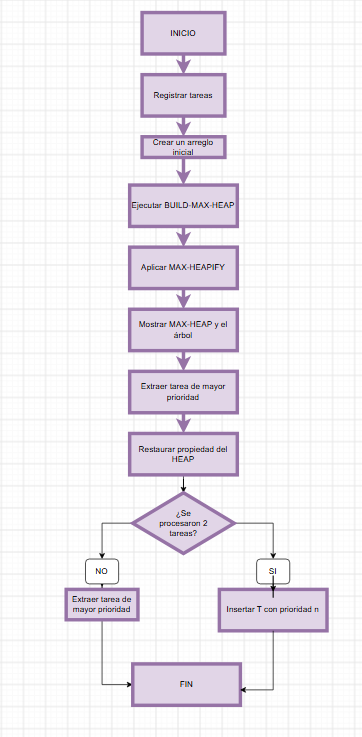

### 5) Análisis de complejidad **[15 pts]**

**Justificación:**

- `MAX-HEAPIFY`: \(O(\log n)\).
- `BUILD-MAX-HEAP`:  \(O(\log n)\)
- `EXTRACT-MAX`: en el mejor caso el elemento que reemplaza la raíz ya cumple la propiedad.

 Kruskal \(O(E\log E)\)

**Justificación:**

- El ordenamiento de Python puede aprovechar secuencias ya ordenadas, por lo que su mejor caso es lineal. En el peor caso ordena las \(E\) aristas en \(O(E\log E)\).

|---|---|

| \(T(n)=1\) | Tiempo constante: \(O(1)\) |

| \(T(n)=\log_2 n\) | Crecimiento logarítmico: \(O(\log n)\) |

| \(T(n)=n\) | Crecimiento lineal: \(O(n)\) |

| \(T(n)=n\log_2 n\) | Crecimiento lineal-logarítmico: \(O(n\log n)\) |

| \(T(n)=n^2\) | Crecimiento cuadrático: \(O(n^2)\) |


## 6) Código funcional **[15 pts]**

A continuación se presenta la implementación completa de los cinco puntos del parcial. Los algoritmos de Max-Heap y Kruskal se desarrollan manualmente; no se utiliza `heapq` ni una función de librería que calcule directamente el MST.

In [ ]:
import math
import matplotlib.pyplot as plt


## Punto 1

In [1]:
tasks = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor",      10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara",      8),
    ("T05", "Generar respaldo",    3),
    ("T06", "Configurar alarma",   7),
]

initial_array = [(p, c, t) for c, t, p in tasks]

def fmt(heap):
    return "[" + ", ".join(f"{c}:{p}" for p, c, _ in heap) + "]"

def left(i): return 2 * i + 1
def right(i):   return 2 * i + 2
def parent(i):     return (i - 1) // 2

In [2]:
def max_heapify(A, i, heap_size):
    l, r = left(i), right(i)
    largest = i
    if l < heap_size and A[l][0] > A[largest][0]:
        largest = l
    if r < heap_size and A[r][0] > A[largest][0]:
        largest = r
    if largest != i:
        A[i], A[largest] = A[largest], A[i]
        max_heapify(A, largest, heap_size)


def build_max_heap(A, verbose=False):
    n = len(A)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(A, i, n)
        if verbose:
            print(f"  max_heapify en i={i}: {fmt(A)}")


def es_max_heap(A):
    return all(A[parent(i)][0] >= A[i][0] for i in range(1, len(A)))

In [3]:
def dibujar_heap(A, titulo="Heap"):
    n = len(A)
    niveles = int(math.log2(n)) + 1 if n else 1
    pos = {}
    for i in range(n):
        nivel = int(math.log2(i + 1))
        k = i - (2 ** nivel - 1)
        pos[i] = ((k + 0.5) / 2 ** nivel, -level)

    fig, ax = plt.subplots(figsize=(7, 1.2 + 1.3 * niveles))
    for i in range(1, n):
        x1, y1 = pos[parent(i)]; x2, y2 = pos[i]
        ax.plot([x1, x2], [y1, y2], color="gray", zorder=1)
    for i in range(n):
        x, y = pos[i]
        p, c, _ = A[i]
        ax.scatter(x, y, s=1500, color="#cfe8ff" if i else "#ffd9a0", edgecolor="black", zorder=2)
        ax.text(x, y, f"{c}\n{p}", ha="center", va="center", fontsize=9, zorder=3)
        ax.text(x + 0.035, y + 0.28, f"i={i}", fontsize=7, color="gray")
    ax.set_title(titulo)
    ax.axis("off")
    ax.set_ylim(-niveles + 0.4, 0.6)
    ax.set_xlim(-0.08, 1.08)
    plt.show()


def mostrar_heap(A, titulo):
    print(f"{titulo}")
    print("  Arreglo:", fmt(A))
    print("  ¿Cumple propiedad Max-Heap?", es_max_heap(A))
    dibujar_heap(A, titulo)

## Punto 2

In [5]:
def extract_max(A):
    if not A:
        raise IndexError("heap vacío")
    maximo = A[0]
    A[0] = A[-1]
    A.pop()
    if A:
        max_heapify(A, 0, len(A))
    return maximo


def insert_max_heap(A, tarea):
    A.append(tarea)
    i = len(A) - 1
    while i > 0 and A[parent(i)][0] < A[i][0]:
        A[i], A[parent(i)] = A[parent(i)], A[i]
        i = parent(i)

In [6]:
tareas_procesadas = []
for k in range(1, 3):
    p, codigo, descripcion = extract_max(heap)
    tareas_procesadas.append((p, codigo, descripcion))
    print(f"=== EXTRACT-MAX #{k} ===")
    print(f"Tarea procesada: {codigo} - {descripcion} - Prioridad {p}")
    mostrar_heap(heap, f"Heap después de la extracción #{k}")
    print()

=== EXTRACT-MAX #1 ===
Tarea procesada: T01 - Configurar servidor - Prioridad 6
Heap después de la extracción #1
  Arreglo: [T02:10, T04:8, T03:4, T06:7, T05:3]
  ¿Cumple propiedad Max-Heap? True


NameError: name 'math' is not defined

In [7]:
nueva = (12, "T07", "Falla en sistema contra incendios")
insert_max_heap(heap, nueva)
print("=== INSERCIÓN ===")
print("Se agregó: T07 - Falla en sistema contra incendios - Prioridad 12")
mostrar_heap(heap, "Heap después de insertar T07")

=== INSERCIÓN ===
Se agregó: T07 - Falla en sistema contra incendios - Prioridad 12
Heap después de insertar T07
  Arreglo: [T07:12, T04:8, T02:10, T06:7, T05:3, T03:4]
  ¿Cumple propiedad Max-Heap? True


NameError: name 'math' is not defined

## Punto 3

In [8]:
dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Cámara",   7, 3),
    "C": ("Sensor",   4, 7),
    "D": ("Alarma",  10, 8),
    "E": ("Router",  13, 3),
    "F": ("Panel",   15, 7),
}

fig, ax = plt.subplots(figsize=(7, 5))
for id_, (nombre, x, y) in dispositivos.items():
    ax.scatter(x, y, s=250, color="#4c9be8", edgecolor="black", zorder=3)
    ax.annotate(f"{id_} - {nombre}\n({x}, {y})", (x, y), textcoords="offset points",
                xytext=(0, 14), ha="center", fontsize=9)
ax.set_title("Posición de los dispositivos")
ax.set_xlabel("X"); ax.set_ylabel("Y")
ax.set_xlim(0, 17); ax.set_ylim(0, 10)
ax.set_aspect("equal"); ax.grid(alpha=0.3)
plt.show()

NameError: name 'plt' is not defined

In [9]:
def distancia(a, b):
    _, x1, y1 = dispositivos[a]
    _, x2, y2 = dispositivos[b]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)


ids = list(dispositivos.keys())

aristas = [(ids[i], ids[j], distancia(ids[i], ids[j]))
           for i in range(len(ids)) for j in range(i + 1, len(ids))]

print(f"Número de aristas: {len(aristas)}  (= 6·5/2)\n")
print("Distancia entre cada pareja de dispositivos:")
for u, v, w in aristas:
    print(f"  {u} - {v} : {w:.2f}")

print("\nMatriz de distancias:")
print("      " + "".join(f"{j:>7}" for j in ids))
for i in ids:
    print(f"  {i}   " + "".join(f"{distancia(i, j):>7.2f}" for j in ids))

NameError: name 'math' is not defined

## Punto 4


In [10]:
class UnionFind:
    def __init__(self, elements):
        self.parent = {e: e for e in elements}
        self.rank = {e: 0 for e in elements}

    def find(self, x):
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1
        return True


def kruskal(vertices, aristas, verbose=True):
    """Devuelve (aristas_mst, costo_total)."""
    ordenadas = sorted(aristas, key=lambda e: e[2])
    uf = UnionFind(vertices)
    mst, total = [], 0.0

    for u, v, w in ordenadas:
        if len(mst) == len(vertices) - 1:
            break
        if uf.union(u, v):
            mst.append((u, v, w))
            total += w
            if verbose:
                print(f"  ACEPTA  {u} - {v} : {w:.2f}")
        elif verbose:
            print(f"  descarta {u} - {v} : {w:.2f}  (formaría un ciclo)")
    return mst, total


print("Aristas ordenadas por peso:")
for u, v, w in sorted(aristas, key=lambda e: e[2]):
    print(f"  {u} - {v} : {w:.2f}")

print("\nEjecución de Kruskal:")
mst, total_cable = kruskal(ids, aristas)

Aristas ordenadas por peso:


NameError: name 'aristas' is not defined

In [11]:
print("Conexiones seleccionadas (MST):")
for u, v, w in mst:
    print(f"{u} - {v} : {w:.2f}")
print(f"Longitud total de cable: {total_cable:.2f}")

assert len(mst) == 5, "El MST debe tener exactamente 5 conexiones"
uf_check = UnionFind(ids)
assert all(uf_check.union(u, v) for u, v, _ in mst), "El MST no debe tener ciclos"
assert len({uf_check.find(i) for i in ids}) == 1, "Los 6 dispositivos deben quedar conectados"
print("\n✔ 5 conexiones, sin ciclos y los 6 dispositivos conectados.")

Conexiones seleccionadas (MST):


NameError: name 'mst' is not defined

## Punto 5


## 7) Tests aplicados **[15 pts]**

Se realizan pruebas para verificar las propiedades del Max-Heap, las extracciones, la inserción de T07, el cálculo de las distancias y la validez del árbol de expansión mínima.

Las pruebas comprueban que:
- La raíz del Max-Heap tenga la prioridad máxima.
- Cada padre tenga prioridad mayor o igual que sus hijos.
- Se extraigan primero T02 y T04, que son las dos tareas con mayor prioridad inicial.
- T07 quede como raíz después de insertarse con prioridad 12.
- Se generen 15 distancias para los seis dispositivos.
- El MST tenga exactamente cinco aristas, conecte los seis dispositivos y no tenga ciclos.
- La longitud total corresponda a la suma de los pesos seleccionados.

In [12]:
def verificar_max_heap(A):
    for i in range(len(A)):
        izq = 2 * i + 1
        der = 2 * i + 2
        if izq < len(A) and A[i][0] < A[izq][0]:
            return False
        if der < len(A) and A[i][0] < A[der][0]:
            return False
    return True

assert verificar_max_heap(heap), "El Heap final después de la inserción debe conservar la propiedad Max-Heap."
assert heap[0][1] == "T07", "T07 debe quedar en la raíz después de insertarse con prioridad 12."
assert len(initial_array) == 6, "Deben registrarse seis tareas iniciales."

assert [x[1] for x in tareas_procesadas] == ["T02", "T04"], "Las dos tareas procesadas deben ser T02 and T04."

assert len(dispositivos) == 6, "Deben existir seis dispositivos."
assert len(aristas) == 15, "Un grafo completo de seis vértices debe tener 15 aristas."

assert len(mst) == 5, "El MST debe contener exactamente cinco conexiones."
assert len({v for arista in mst for v in arista[:2]}) == 6, "Las conexiones deben incluir los seis dispositivos."
assert math.isclose(total_cable, sum(peso for _, _, peso in mst), rel_tol=1e-9), "El total debe ser la suma de los pesos del MST."
assert math.isclose(total_cable, 25.50, abs_tol=0.02), "El costo total esperado del MST es aproximadamente 25.50."

print("Todas las pruebas fueron superadas correctamente.")

AssertionError: Las dos tareas procesadas deben ser T02 and T04.